# Feature Engineering

In [297]:
#load the processed dataset created by EDA.ipynb

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path("..")
input_path = (
    project_root / "data" / "processed" / "energy_data_eda.csv"
)

df = pd.read_csv(input_path, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [298]:
#TIME BASED FEATURE ENGINEERING

#make sure date is in datetime format
df["date"] = pd.to_datetime(df["date"])

#sort data chronologically
df = df.sort_values("date").reset_index(drop=True)

#extract useful time based features
df["hour"] = df["date"].dt.hour
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["day_of_month"] = df["date"].dt.day

# Weekend indicator : 1 = Saturday/Sunday, 0 = weekday
df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)

# Display the new and existing time based features
display(
    df[
        ["date", "hour", "day_of_week",
         "month", "day_of_month", "is_weekend"]
    ].head(10)
)

/var/folders/8y/kj2ttrds0x9cjtzq28y1qnkm0000gn/T/ipykernel_69041/4140900998.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek
/var/folders/8y/kj2ttrds0x9cjtzq28y1qnkm0000gn/T/ipykernel_69041/4140900998.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)


,date,hour,day_of_week,month,day_of_month,is_weekend
0,2016-01-11 17:00:00,17,0,1,11,0
1,2016-01-11 17:10:00,17,0,1,11,0
2,2016-01-11 17:20:00,17,0,1,11,0
3,2016-01-11 17:30:00,17,0,1,11,0
4,2016-01-11 17:40:00,17,0,1,11,0
5,2016-01-11 17:50:00,17,0,1,11,0
6,2016-01-11 18:00:00,18,0,1,11,0
7,2016-01-11 18:10:00,18,0,1,11,0
8,2016-01-11 18:20:00,18,0,1,11,0
9,2016-01-11 18:30:00,18,0,1,11,0


Records by hour:


hour
0     822
1     822
2     822
3     822
4     822
5     822
6     822
7     822
8     822
9     822
10    822
11    822
12    822
13    822
14    822
15    822
16    822
17    828
18    823
19    822
20    822
21    822
22    822
23    822
Name: count, dtype: int64


Weekday/weekend counts:


is_weekend
Weekday    14263
Weekend     5472
Name: count, dtype: int64

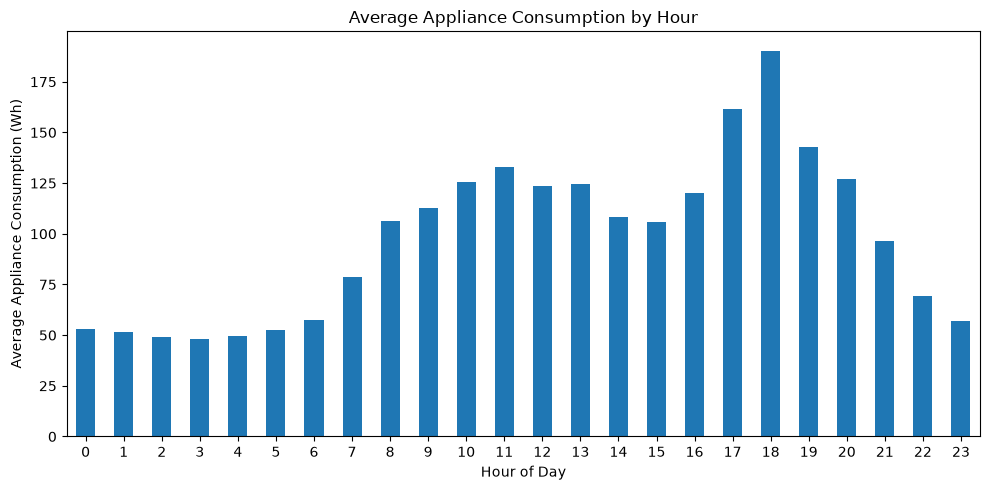

In [299]:
# Check the number of records for each hour
print("Records by hour:")
display(df["hour"].value_counts().sort_index())

# Check weekday and weekend records
print("\nWeekday/weekend counts:")
display(
    df["is_weekend"]
    .map({0: "Weekday", 1: "Weekend"})
    .value_counts()
)

# Visualize average appliance consumption by hour
hourly_consumption = df.groupby("hour")["Appliances"].mean()

plt.figure(figsize=(10, 5))
hourly_consumption.plot(kind="bar")

plt.title("Average Appliance Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Appliance Consumption (Wh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [300]:
# Check the time interval between consecutive records

df = df.sort_values("date").reset_index(drop=True)

time_difference = df["date"].diff()

print("Most common time intervals:")
display(time_difference.value_counts().head(10))

print("\nIntervals that are not exactly 10 minutes:")
print(
    (time_difference.iloc[1:] != pd.Timedelta(minutes=10)).sum()
)

Most common time intervals:


date
0 days 00:10:00    19734
Name: count, dtype: int64


Intervals that are not exactly 10 minutes:
0


In [301]:
#ROLLING AVERAGES AND MOVING WINDOWS

#ensure observations are in chronological order
df = df.sort_values("date").reset_index(drop=True)

#shift consumption by one row so the current target is excluded
previous_consumption = df["Appliances"].shift(1)

#previous 1-hour average: 6 previous readings
df["rolling_mean_1h"] = (
    previous_consumption
    .rolling(window=6, min_periods=6)
    .mean()
)

# Previous 3-hour average: 18 previous readings
df["rolling_mean_3h"] = (
    previous_consumption
    .rolling(window=18, min_periods=18)
    .mean()
)

# Previous 1-hour standard deviation
df["rolling_std_1h"] = (
    previous_consumption
    .rolling(window=6, min_periods=6)
    .std()
)

# Inspect the results
display(
    df[
        [
            "date",
            "Appliances",
            "rolling_mean_1h",
            "rolling_mean_3h",
            "rolling_std_1h"
        ]
    ].head(25)
)

,date,Appliances,rolling_mean_1h,rolling_mean_3h,rolling_std_1h
0,2016-01-11 17:00:00,60,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,NaN,NaN,NaN
2,2016-01-11 17:20:00,50,NaN,NaN,NaN
3,2016-01-11 17:30:00,50,NaN,NaN,NaN
4,2016-01-11 17:40:00,60,NaN,NaN,NaN
5,2016-01-11 17:50:00,50,NaN,NaN,NaN
6,2016-01-11 18:00:00,60,55.000000,NaN,5.477226
7,2016-01-11 18:10:00,60,55.000000,NaN,5.477226
8,2016-01-11 18:20:00,60,55.000000,NaN,5.477226
9,2016-01-11 18:30:00,70,56.666667,NaN,5.163978


In [302]:
# Inspect the rolling feature columns and their missing values

rolling_columns = [
    "rolling_mean_1h",
    "rolling_mean_3h",
    "rolling_std_1h"
]

display(df[["date", "Appliances"] + rolling_columns].head(25))

print("\nMissing values in rolling features:")
print(df[rolling_columns].isna().sum())

,date,Appliances,rolling_mean_1h,rolling_mean_3h,rolling_std_1h
0,2016-01-11 17:00:00,60,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,NaN,NaN,NaN
2,2016-01-11 17:20:00,50,NaN,NaN,NaN
3,2016-01-11 17:30:00,50,NaN,NaN,NaN
4,2016-01-11 17:40:00,60,NaN,NaN,NaN
5,2016-01-11 17:50:00,50,NaN,NaN,NaN
6,2016-01-11 18:00:00,60,55.000000,NaN,5.477226
7,2016-01-11 18:10:00,60,55.000000,NaN,5.477226
8,2016-01-11 18:20:00,60,55.000000,NaN,5.477226
9,2016-01-11 18:30:00,70,56.666667,NaN,5.163978



Missing values in rolling features:
rolling_mean_1h     6
rolling_mean_3h    18
rolling_std_1h      6
dtype: int64


In [303]:
#LAGGED FEATURES

# Ensure the data is sorted chronologically
df = df.sort_values("date").reset_index(drop=True)

# Previous appliance consumption values
df["lag_1"] = df["Appliances"].shift(1)  # 10 minutes ago
df["lag_3"] = df["Appliances"].shift(3)  # 30 minutes ago
df["lag_6"] = df["Appliances"].shift(6)  # 1 hour ago

# Display the results
display(
    df[
        [
            "date",
            "Appliances",
            "lag_1",
            "lag_3",
            "lag_6"
        ]
    ].head(12)
)

# Check missing values in lag features
print("\nMissing values in lag features:")
print(df[["lag_1", "lag_3", "lag_6"]].isna().sum())

,date,Appliances,lag_1,lag_3,lag_6
0,2016-01-11 17:00:00,60,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,60.0,NaN,NaN
2,2016-01-11 17:20:00,50,60.0,NaN,NaN
3,2016-01-11 17:30:00,50,50.0,60.0,NaN
4,2016-01-11 17:40:00,60,50.0,60.0,NaN
5,2016-01-11 17:50:00,50,60.0,50.0,NaN
6,2016-01-11 18:00:00,60,50.0,50.0,60.0
7,2016-01-11 18:10:00,60,60.0,60.0,60.0
8,2016-01-11 18:20:00,60,60.0,50.0,50.0
9,2016-01-11 18:30:00,70,60.0,60.0,50.0



Missing values in lag features:
lag_1    1
lag_3    3
lag_6    6
dtype: int64


<Figure size 1200x500 with 0 Axes>

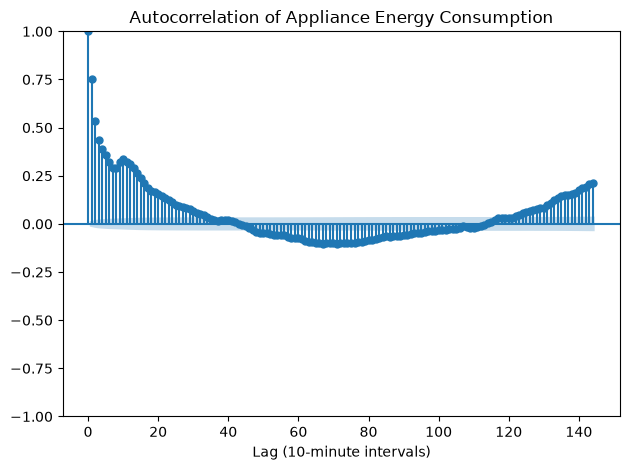

In [304]:
#AUTOCORRELATION ANALYSIS

from statsmodels.graphics.tsaplots import plot_acf

# Plot autocorrelation for appliance consumption
plt.figure(figsize=(12, 5))

plot_acf(
    df["Appliances"],
    lags=144,  # 144 readings = 24 hours at 10min intervals
    missing="drop"
)

plt.title("Autocorrelation of Appliance Energy Consumption")
plt.xlabel("Lag (10-minute intervals)")
plt.tight_layout()
plt.show()


In [305]:
#Check the columns available for interaction features

print("Temperature columns:")
print([col for col in df.columns if col.startswith("T")])

print("\nHumidity columns:")
print([col for col in df.columns if col.startswith("RH")])

Temperature columns:
['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T_out', 'Tdewpoint']

Humidity columns:
['RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9', 'RH_out']


In [306]:
#INTERACTION FEATURES

# Combine indoor temperature and humidity
df["temp_humidity_interaction"] = df["T1"] * df["RH_1"]

# Display the original features and the new interaction
display(
    df[
        [
            "date",
            "T1",
            "RH_1",
            "temp_humidity_interaction",
            "Appliances"
        ]
    ].head(10)
)

# Check the new feature
print(
    "\nMissing values in interaction feature:",
    df["temp_humidity_interaction"].isna().sum()
)

print(
    "Interaction feature statistics:"
)
display(df["temp_humidity_interaction"].describe())

,date,T1,RH_1,temp_humidity_interaction,Appliances
0,2016-01-11 17:00:00,19.890000,47.596667,946.697700,60
1,2016-01-11 17:10:00,19.890000,46.693333,928.730400,60
2,2016-01-11 17:20:00,19.890000,46.300000,920.907000,50
3,2016-01-11 17:30:00,19.890000,46.066667,916.266000,50
4,2016-01-11 17:40:00,19.890000,46.333333,921.570000,60
5,2016-01-11 17:50:00,19.890000,46.026667,915.470400,50
6,2016-01-11 18:00:00,19.890000,45.766667,910.299000,60
7,2016-01-11 18:10:00,19.856667,45.560000,904.669733,60
8,2016-01-11 18:20:00,19.790000,45.597500,902.374525,60
9,2016-01-11 18:30:00,19.856667,46.090000,915.193767,70



Missing values in interaction feature: 0
Interaction feature statistics:


count    19735.000000
mean       874.143820
std        119.144381
min        621.536667
25%        787.740533
50%        857.152000
75%        936.336000
max       1380.614400
Name: temp_humidity_interaction, dtype: float64

In [307]:
# Compare correlations with appliance consumption

correlation_values = df[
    ["T1", "RH_1", "temp_humidity_interaction", "Appliances"]
].corr(numeric_only=True)

print("Correlation with Appliances:")
display(correlation_values["Appliances"].sort_values(ascending=False))

Correlation with Appliances:


Appliances                   1.000000
temp_humidity_interaction    0.094550
RH_1                         0.086031
T1                           0.055447
Name: Appliances, dtype: float64

In [308]:
#DOMAIN SPECIFIC FEATURE CHECK

# Inspect available columns related to dates or external factors
print("Columns available for domain specific analysis  :")

print([
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "holiday", "event", "weather",
            "weekday", "weekstatus", "weekend"
        ]
    )
])

# Check the dataset date range
print("\nDataset date range:")
print(df["date"].min(), "to", df["date"].max())

# Check whether a weekday/weekend indicator already exists
if "is_weekend" in df.columns:
    print("\nWeekend indicator counts:")
    print(df["is_weekend"].value_counts().sort_index())

Columns available for domain specific analysis  :
['is_weekend']

Dataset date range:
2016-01-11 17:00:00 to 2016-05-27 18:00:00

Weekend indicator counts:
is_weekend
0    14263
1     5472
Name: count, dtype: int64


In [309]:
#FEATURE SELECTION - PREPARATION

# Candidate numeric features
candidate_features = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in ["Appliances", "rv2"]
]

print("Number of candidate features:", len(candidate_features))
print("\nCandidate features:")
print(candidate_features)

print("\nDuplicate-column check:")
print("rv1 and rv2 identical:", df["rv1"].equals(df["rv2"]))

Number of candidate features: 38

Candidate features:
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'hour', 'day_of_week', 'month', 'day_of_month', 'is_weekend', 'rolling_mean_1h', 'rolling_mean_3h', 'rolling_std_1h', 'lag_1', 'lag_3', 'lag_6', 'temp_humidity_interaction']

Duplicate-column check:
rv1 and rv2 identical: True


In [310]:
# Remove duplicate column
df = df.drop(columns=["rv2"])

# Remove rows with missing required features
model_df = df.dropna(
    subset=final_features + ["Appliances"]
).copy()

### Correlation Based Feature Analysis

Top 15 features by absolute correlation:


,Correlation
lag_1,0.756846
rolling_mean_1h,0.586167
rolling_std_1h,0.559987
rolling_mean_3h,0.509129
lag_3,0.439060
lag_6,0.319804
hour,0.225956
lights,0.217602
T2,0.156221
RH_out,-0.153233


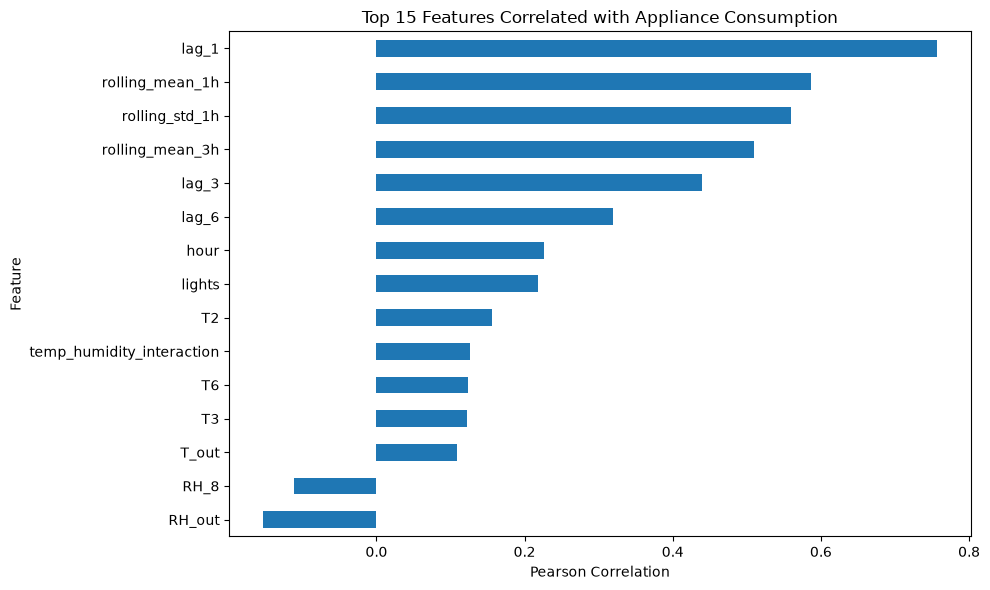

In [311]:
# CORRELATION BASED FEATURE ANALYSIS

# Split point for chronological 80/20 selection
split_index = int(len(df) * 0.80)

# Use only the training period for feature selection
selection_train = df.iloc[:split_index].copy()

# Calculate correlation with the target
correlations = (
    selection_train[candidate_features + ["Appliances"]]
    .corr(numeric_only=True)["Appliances"]
    .drop("Appliances")
    .sort_values(key=abs, ascending=False)
)

# Display strongest relationships
print("Top 15 features by absolute correlation:")
display(correlations.head(15).to_frame("Correlation"))

# Visualize the top 15 correlations
plt.figure(figsize=(10, 6))

correlations.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Features Correlated with Appliance Consumption")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Top 15 features by Random Forest importance:


,Importance
lag_1,0.599413
rolling_mean_1h,0.024489
rolling_mean_3h,0.022785
rolling_std_1h,0.021344
rv1,0.016372
lag_3,0.015058
hour,0.014354
Press_mm_hg,0.013771
T4,0.013227
T3,0.012276


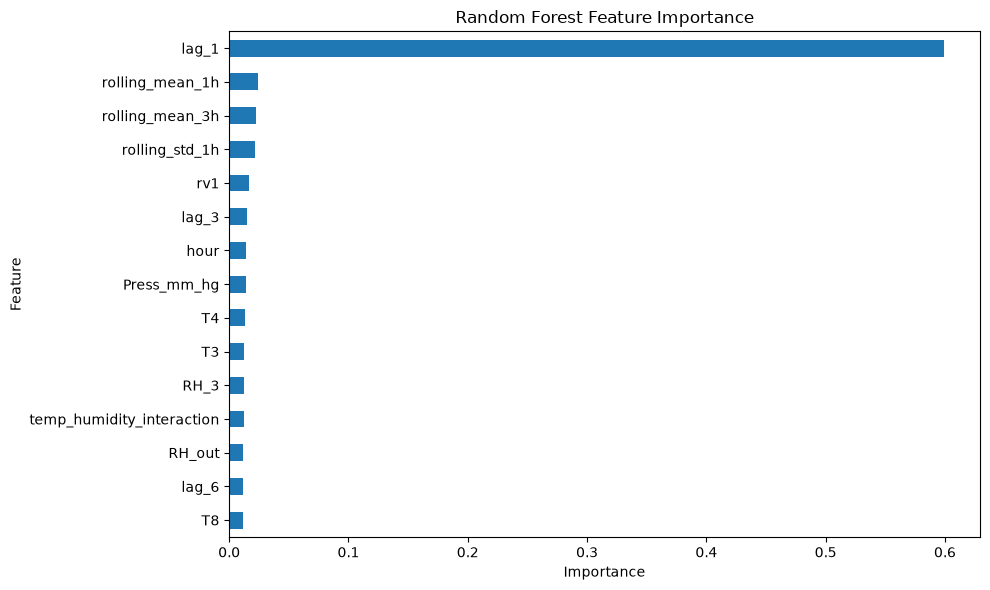

In [312]:
#RANDOM FOREST FEATURE IMPORTANCE

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer

# Prepare training features and target
X_selection = selection_train[candidate_features]
y_selection = selection_train["Appliances"]

# Temporarily fill initial rolling/lag NaNs
# using training-feature medians for this diagnostic model
imputer = SimpleImputer(strategy="median")
X_selection_imputed = imputer.fit_transform(X_selection)

# Train a Random Forest for feature ranking
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_selection_imputed, y_selection)

# Rank feature importance
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=candidate_features
).sort_values(ascending=False)

print("Top 15 features by Random Forest importance:")
display(feature_importance.head(15).to_frame("Importance"))

# Plot the top 15 features
plt.figure(figsize=(10, 6))

feature_importance.head(15).sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Top 15 features correlated with Appliances:


,Correlation
lag_1,0.756846
rolling_mean_1h,0.586167
rolling_std_1h,0.559987
rolling_mean_3h,0.509129
lag_3,0.439060
lag_6,0.319804
hour,0.225956
lights,0.217602
T2,0.156221
RH_out,-0.153233


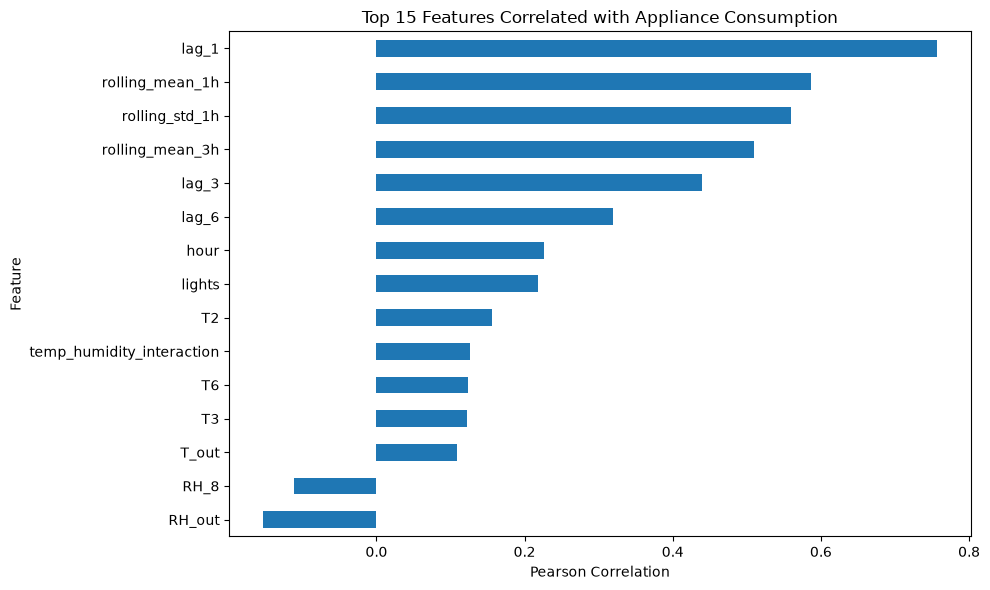

In [313]:

#Feature correlation analysis

# Use only the first 80% of the chronological data
split_index = int(len(df) * 0.80)
selection_train = df.iloc[:split_index].copy()

# Calculate each feature's correlation with appliance consumption
correlations = (
    selection_train[candidate_features + ["Appliances"]]
    .corr(numeric_only=True)["Appliances"]
    .drop("Appliances")
    .sort_values(key=abs, ascending=False)
)

# Display the 15 features with the strongest absolute correlations
print("Top 15 features correlated with Appliances:")
display(correlations.head(15).to_frame("Correlation"))

# Visualize the results
plt.figure(figsize=(10, 6))

correlations.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Features Correlated with Appliance Consumption")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [314]:

# Check correlations between candidate input features
# using only the first 80% of chronological data.

feature_corr = selection_train[candidate_features].corr()

# Find pairs with a strong absolute correlation
threshold = 0.90

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() >= threshold
].sort_values(
    "Correlation",
    key=abs,
    ascending=False
)

print("Highly correlated feature pairs (|correlation| >= 0.90):")
display(high_corr_pairs)


Highly correlated feature pairs (|correlation| >= 0.90):


,Feature 1,Feature 2,Correlation
437,T6,T_out,0.971046
236,RH_3,RH_4,0.901755


### Recursive Feature Elimination (RFE)

In [315]:
#RECURSIVE FEATURE ELIMINATION (RFE) - LINEAR REGRESSION

from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

# Remove the first rows where lag and rolling features are not available yet
rfe_train = selection_train.dropna(subset=candidate_features)

# Standardize features so the linear coefficients are comparable
rfe_scaler = StandardScaler()
X_rfe = rfe_scaler.fit_transform(rfe_train[candidate_features])
y_rfe = rfe_train["Appliances"]

# Remove the feature with the smallest coefficient one at a time
# and use chronological cross-validation to choose how many to keep
rfecv = RFECV(
    estimator=LinearRegression(),
    step=1,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

rfecv.fit(X_rfe, y_rfe)

rfe_lr_selected = [
    feature for feature, keep in zip(candidate_features, rfecv.support_) if keep
]

print("Optimal number of features:", rfecv.n_features_)
print("\nSelected features:")
print(rfe_lr_selected)
print("\nRemoved features:")
print([feature for feature in candidate_features if feature not in rfe_lr_selected])

Optimal number of features: 1

Selected features:
['lag_1']

Removed features:
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'hour', 'day_of_week', 'month', 'day_of_month', 'is_weekend', 'rolling_mean_1h', 'rolling_mean_3h', 'rolling_std_1h', 'lag_3', 'lag_6', 'temp_humidity_interaction']


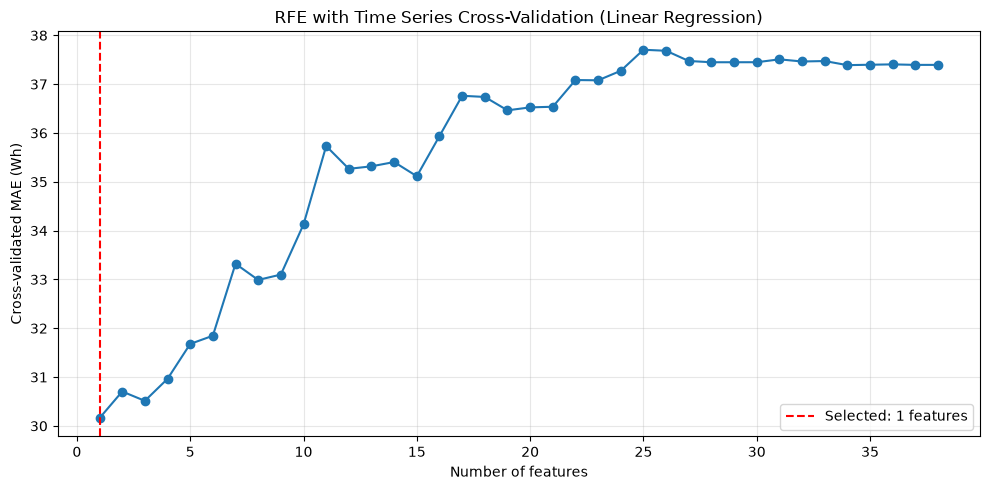

MAE with 1 feature: 30.16
MAE with selected features: 30.16
MAE with all features: 37.39


In [316]:
# Cross validated MAE for each number of features

cv_mae = -rfecv.cv_results_["mean_test_score"]
n_features = rfecv.cv_results_["n_features"]

plt.figure(figsize=(10, 5))

plt.plot(n_features, cv_mae, marker="o")

plt.axvline(
    rfecv.n_features_,
    color="red",
    linestyle="--",
    label=f"Selected: {rfecv.n_features_} features"
)

plt.title("RFE with Time Series Cross-Validation (Linear Regression)")
plt.xlabel("Number of features")
plt.ylabel("Cross-validated MAE (Wh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("MAE with 1 feature:", round(cv_mae[0], 2))
print("MAE with selected features:", round(cv_mae[rfecv.n_features_ - 1], 2))
print("MAE with all features:", round(cv_mae[-1], 2))

In [317]:
#RECURSIVE FEATURE ELIMINATION (RFE) - RANDOM FOREST

rfe_rf = RFE(
    estimator=RandomForestRegressor(
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ),
    n_features_to_select=15,
    step=2  # remove 2 features per round to reduce training time
)

rfe_rf.fit(rfe_train[candidate_features], y_rfe)

rfe_rf_selected = [
    feature for feature, keep in zip(candidate_features, rfe_rf.support_) if keep
]

print("Features selected by Random Forest RFE:")
print(rfe_rf_selected)

Features selected by Random Forest RFE:
['RH_2', 'T3', 'RH_3', 'T4', 'RH_5', 'T6', 'T8', 'Press_mm_hg', 'rv1', 'hour', 'rolling_mean_1h', 'rolling_mean_3h', 'rolling_std_1h', 'lag_1', 'lag_3']


In [318]:
# Compare the rankings from all feature selection methods

selection_summary = pd.DataFrame({
    "Correlation Rank": correlations.abs().rank(ascending=False, method="min"),
    "RF Importance Rank": feature_importance.rank(ascending=False, method="min"),
    "RFE Rank (Linear Regression)": pd.Series(rfecv.ranking_, index=candidate_features),
    "RFE Rank (Random Forest)": pd.Series(rfe_rf.ranking_, index=candidate_features)
}).astype(int)

selection_summary["Selected by RFE (LR)"] = selection_summary.index.isin(rfe_lr_selected)
selection_summary["Selected by RFE (RF)"] = selection_summary.index.isin(rfe_rf_selected)

selection_summary = selection_summary.sort_values("RF Importance Rank")

display(selection_summary)

# Features both RFE methods agree on
selected_by_both = [
    feature for feature in rfe_lr_selected if feature in rfe_rf_selected
]

print("Selected by both RFE methods:", len(selected_by_both))
print(selected_by_both)

print("\nNot selected by either RFE method:")
print([
    feature for feature in candidate_features
    if feature not in rfe_lr_selected and feature not in rfe_rf_selected
])

,Correlation Rank,RF Importance Rank,RFE Rank (Linear Regression),RFE Rank (Random Forest),Selected by RFE (LR),Selected by RFE (RF)
lag_1,1,1,1,1,True,True
rolling_mean_1h,2,2,14,1,False,True
rolling_mean_3h,4,3,2,1,False,True
rolling_std_1h,3,4,24,1,False,True
rv1,33,5,31,1,False,True
lag_3,5,6,15,1,False,True
hour,7,7,19,1,False,True
Press_mm_hg,27,8,27,1,False,True
T4,20,9,12,1,False,True
T3,13,10,23,1,False,True


Selected by both RFE methods: 1
['lag_1']

Not selected by either RFE method:
['lights', 'T1', 'RH_1', 'T2', 'RH_4', 'T5', 'RH_6', 'T7', 'RH_7', 'RH_8', 'T9', 'RH_9', 'T_out', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'day_of_week', 'month', 'day_of_month', 'is_weekend', 'lag_6', 'temp_humidity_interaction']


In [319]:

# Define the final candidate input features

excluded_columns = ["date", "Appliances", "rv1", "rv2"]

final_features = [
    col
    for col in df.select_dtypes(include=np.number).columns
    if col not in excluded_columns
]

print("Number of candidate features:", len(final_features))
print("\nFinal candidate features:")
print(final_features)


Number of candidate features: 37

Final candidate features:
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour', 'day_of_week', 'month', 'day_of_month', 'is_weekend', 'rolling_mean_1h', 'rolling_mean_3h', 'rolling_std_1h', 'lag_1', 'lag_3', 'lag_6', 'temp_humidity_interaction']


In [320]:

#Remove rows with missing values in required features

model_df = df.dropna(
    subset=final_features + ["Appliances"]
).copy()

model_df = model_df.sort_values("date").reset_index(drop=True)

print("Original records:", len(df))
print("Records after feature preparation:", len(model_df))
print("Rows removed:", len(df) - len(model_df))
print("\nMissing values in model data:", model_df[final_features + ["Appliances"]].isna().sum().sum())


Original records: 19735
Records after feature preparation: 19717
Rows removed: 18

Missing values in model data: 0


In [321]:

# Split chronologically first 80% for training, last 20% for testing

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Training ends:", train_df["date"].max())
print("Testing starts:", test_df["date"].min())


Training records: 15773
Testing records: 3944
Training ends: 2016-04-30 08:40:00
Testing starts: 2016-04-30 08:50:00


In [322]:

#Validate the prepared data

print("Training features missing values:",
      train_df[final_features].isna().sum().sum())

print("Testing features missing values:",
      test_df[final_features].isna().sum().sum())

print("Training target missing values:",
      train_df["Appliances"].isna().sum())

print("Testing target missing values:",
      test_df["Appliances"].isna().sum())

assert train_df["date"].max() < test_df["date"].min()
assert train_df[final_features].notna().all().all()
assert test_df[final_features].notna().all().all()

print("\nData preparation checks passed")


Training features missing values: 0
Testing features missing values: 0
Training target missing values: 0
Testing target missing values: 0

Data preparation checks passed


In [323]:

# Check missing values in the engineered dataset

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

display(missing.to_frame("Missing Values"))

print("Total missing values:", df.isna().sum().sum())
print("Total rows:", len(df))


,Missing Values
rolling_mean_3h,18
rolling_mean_1h,6
rolling_std_1h,6
lag_6,6
lag_3,3
lag_1,1


Total missing values: 40
Total rows: 19735


In [324]:

# Remove rows missing values in required model features
# Keep the original df unchanged

model_df = df.dropna(
    subset=final_features + ["Appliances"]
).copy()

model_df = model_df.sort_values("date").reset_index(drop=True)

print("Original rows:", len(df))
print("Prepared rows:", len(model_df))
print("Rows removed:", len(df) - len(model_df))
print("Remaining missing values:", model_df.isna().sum().sum())


Original rows: 19735
Prepared rows: 19717
Rows removed: 18
Remaining missing values: 0


In [325]:

# Cell 28: Prepare, save, and verify the final engineered dataset

from pathlib import Path
import pandas as pd

# 1. Remove rows missing required engineered features
model_df = df.dropna(
    subset=final_features + ["Appliances"]
).copy()

# 2. Preserve chronological order
model_df = model_df.sort_values("date").reset_index(drop=True)

# 3. Define the output path
output_path = (
    Path("..")
    / "data"
    / "processed"
    / "energy_data_features.csv"
)

# 4. Create the output folder if necessary
output_path.parent.mkdir(parents=True, exist_ok=True)

# 5. Save model_df, NOT df
model_df.to_csv(output_path, index=False)

# 6. Reload the saved file and verify it
saved_df = pd.read_csv(output_path, parse_dates=["date"])

print("Saved dataset:", output_path.resolve())
print("Dataset shape:", saved_df.shape)
print("Rows removed:", len(df) - len(saved_df))
print("Total missing values:", saved_df.isna().sum().sum())
print("Dates sorted:", saved_df["date"].is_monotonic_increasing)

# 7. Validate the output
assert saved_df.isna().sum().sum() == 0
assert saved_df["date"].is_monotonic_increasing
assert saved_df["Appliances"].notna().all()

print("\nValidation passed")


Saved dataset: /Users/mohamedafrar/Documents/Multivariate-Time-Series-Prediction-Using-Deep-Learning/data/processed/energy_data_features.csv
Dataset shape: (19717, 40)
Rows removed: 18
Total missing values: 0
Dates sorted: True

Validation passed
